# Robinson harvest analysis

In [1]:
from pathlib import Path
import os
from IPython.display import display, Image

ROOT = Path.cwd()
if ROOT.name == "04_robinson":
    ROOT = ROOT.parent.parent
if not (ROOT / "batches").is_dir():
    raise FileNotFoundError("Open this notebook from the project folder.")
BATCH_DIR = ROOT / "batches/04_robinson"
os.chdir(BATCH_DIR)
%matplotlib inline

## Workbook

One recorded harvest. Weights in grams.

In [2]:
from __future__ import annotations

import re

from pathlib import Path

import matplotlib.pyplot as plt

import pandas as pd

workbook = ROOT / "data/processed/Harvest 2026 Sapkota lab CLEANED.xlsx"

rc_sheet = "RC_01_First_2026-08-12"

metadata_sheet = "RC_Entry_Metadata"

figures = Path("figures")

figures.mkdir(exist_ok=True)

## Harvest rows

In [3]:
rc = pd.read_excel(workbook, sheet_name=rc_sheet)

rc = rc.dropna(how="all").copy()

rc.columns = rc.columns.str.strip()

if "Calculated" in rc.columns:
    rc = rc.rename(columns={"Calculated": "Unmarketables (counts)"})

for column in ["Genotypes", "Location", "Harvest"]:
    if column in rc.columns:
        rc[column] = rc[column].astype("string").str.strip()

rc["Genotype_raw"] = rc.get("Genotype_raw", rc["Genotypes"])

def clean_genotype(name):
    """Turn UKY-26-015 / 25-3 / UKyt 26-024 into UKYT-26-015 etc."""
    if pd.isna(name):
        return name
    text = str(name).strip()
    uk_line = re.match(
        r"(?i)^(?:uky[t]?\s*-?\s*)?(\d{2})\s*-?\s*(\d{1,3})$",
        text,
    )
    if uk_line:
        year, number = uk_line.group(1), int(uk_line.group(2))
        return f"UKYT-{year}-{number:03d}"
    return text

rc["Genotypes"] = rc["Genotypes"].map(clean_genotype)

rc["Location"] = (
    rc["Location"]
    .astype("string")
    .str.replace(r"\s+", " ", regex=True)
    .str.strip()
    .replace({r"(?i)^robinson(\s*center)?$": "Robinson"}, regex=True)
)

rc["Date of harvest"] = pd.to_datetime(rc["Date of harvest"], errors="coerce")

rc["Harvest"] = rc["Harvest"].fillna("First")

rc["Source Sheet"] = rc_sheet

numeric_columns = [
    "Grade 1 Marketable (weight)",
    "Grade 1 Marketable (counts)",
    "Unmarketables (weight)",
    "Unmarketables (counts)",
    "Weight of 20 marketable (g)",
    "Total Weight (g)",
]

for column in numeric_columns:
    if column in rc.columns:
        rc[column] = pd.to_numeric(rc[column], errors="coerce")
    else:
        rc[column] = pd.NA

## Total weight

Component weights are used where available, with the recorded total as fallback. The total_source column records the choice.

In [4]:
rc["Computed Total Weight (g)"] = rc[
    ["Grade 1 Marketable (weight)", "Unmarketables (weight)"]
].sum(axis=1, min_count=1)

g1 = rc["Grade 1 Marketable (weight)"]

um = rc["Unmarketables (weight)"]

tw = rc["Total Weight (g)"]

both_parts = g1.notna() & um.notna()

only_g1 = g1.notna() & um.isna()

only_um = um.notna() & g1.isna()

neither = g1.isna() & um.isna()

rc["Total Harvest Weight"] = pd.NA

rc["total_source"] = pd.NA

rc.loc[both_parts, "Total Harvest Weight"] = g1[both_parts] + um[both_parts]

rc.loc[both_parts, "total_source"] = "computed_both_parts"

zero_parts_override = (
    both_parts
    & ((g1.fillna(0) + um.fillna(0)) == 0)
    & tw.notna()
    & (tw > 0)
)

rc.loc[zero_parts_override, "Total Harvest Weight"] = tw[zero_parts_override]

rc.loc[zero_parts_override, "total_source"] = "recorded_total_over_zero_parts"

use_tw_with_g1 = only_g1 & tw.notna() & (tw >= g1)

rc.loc[use_tw_with_g1, "Total Harvest Weight"] = tw[use_tw_with_g1]

rc.loc[use_tw_with_g1, "total_source"] = "recorded_total_with_grade1"

rc.loc[only_g1 & ~use_tw_with_g1, "Total Harvest Weight"] = g1[only_g1 & ~use_tw_with_g1]

rc.loc[only_g1 & ~use_tw_with_g1, "total_source"] = "grade1_only"

use_tw_with_um = only_um & tw.notna() & (tw >= um)

rc.loc[use_tw_with_um, "Total Harvest Weight"] = tw[use_tw_with_um]

rc.loc[use_tw_with_um, "total_source"] = "recorded_total_with_unmarketable"

rc.loc[only_um & ~use_tw_with_um, "Total Harvest Weight"] = um[only_um & ~use_tw_with_um]

rc.loc[only_um & ~use_tw_with_um, "total_source"] = "unmarketable_only"

rc.loc[neither & tw.notna(), "Total Harvest Weight"] = tw[neither & tw.notna()]

rc.loc[neither & tw.notna(), "total_source"] = "recorded_total_only"

rc["Total Harvest Weight"] = pd.to_numeric(
    rc["Total Harvest Weight"], errors="coerce"
)

rc["Total Marketable Weight"] = rc["Grade 1 Marketable (weight)"]

rc["Total Marketable Count"] = rc["Grade 1 Marketable (counts)"]

inferred_unm = rc["Total Harvest Weight"] - rc["Total Marketable Weight"]

use_inferred = (
    rc["Unmarketables (weight)"].isna()
    & rc["Total Harvest Weight"].notna()
    & rc["Total Marketable Weight"].notna()
    & inferred_unm.ge(0)
)

rc["Unmarketable Weight for Pct"] = rc["Unmarketables (weight)"]

rc.loc[use_inferred, "Unmarketable Weight for Pct"] = inferred_unm[use_inferred]

rc["Marketable Percentage"] = (
    rc["Total Marketable Weight"] / rc["Total Harvest Weight"] * 100
)

## Fruit size

Weight-of-20 estimates and weight-per-count estimates are kept separate.

In [5]:
rc["Mean Weight Per Marketable Count"] = (
    rc["Total Marketable Weight"] / rc["Total Marketable Count"]
)

rc["Mean Fruit Weight From 20 (g)"] = rc["Weight of 20 marketable (g)"] / 20.0

row_total_count = rc[
    ["Total Marketable Count", "Unmarketables (counts)"]
].sum(axis=1, min_count=1)

rc["Total Count"] = row_total_count

rc["Mean Weight Per Count"] = rc["Total Harvest Weight"] / rc["Total Count"]

master_cols = [
    "SN",
    "Genotype_raw",
    "Genotypes",
    "Location",
    "Date of harvest",
    "Harvest",
    "Source Sheet",
    "Replicate",
    "Grade 1 Marketable (weight)",
    "Grade 1 Marketable (counts)",
    "Unmarketables (weight)",
    "Unmarketables (counts)",
    "Weight of 20 marketable (g)",
    "Total Weight (g)",
    "Computed Total Weight (g)",
    "Total Harvest Weight",
    "total_source",
    "Total Marketable Weight",
    "Total Marketable Count",
    "Unmarketable Weight for Pct",
    "Marketable Percentage",
    "Total Count",
    "Mean Weight Per Count",
    "Mean Weight Per Marketable Count",
    "Mean Fruit Weight From 20 (g)",
]

for c in master_cols:
    if c not in rc.columns:
        rc[c] = pd.NA

robinson_master = rc[master_cols].copy()

robinson_master.to_csv("robinson_harvest_master.csv", index=False)

dup_mask = robinson_master["Genotypes"].duplicated(keep=False)

if dup_mask.any():
    print("\nDuplicate genotype rows (treated as separate plots / summed in summary):")
    print(
        robinson_master.loc[
            dup_mask,
            [
                "SN",
                "Genotypes",
                "Genotype_raw",
                "Grade 1 Marketable (weight)",
                "Unmarketables (weight)",
                "Total Harvest Weight",
            ],
        ].to_string(index=False)
    )


Duplicate genotype rows (treated as separate plots / summed in summary):
 SN   Genotypes Genotype_raw  Grade 1 Marketable (weight)  Unmarketables (weight)  Total Harvest Weight
  3 UKYT-25-001         25-1                       1215.0                   427.0                1642.0
 27    NC25241G   NC 25241 G                       1423.0                  1081.0                2504.0
 29 UKYT-25-001        25-01                        760.0                   930.0                1690.0
 30    NC25241G    NC25241G                        1795.0                  1576.0                3371.0


## Genotype summary

In [6]:
by_geno = robinson_master.groupby("Genotypes", dropna=False)

has_weight = robinson_master["Total Harvest Weight"].notna()

measured = robinson_master.loc[has_weight]

genotype_summary = pd.DataFrame(
    {
        "n_rows": by_geno.size(),
        "n_with_weight": measured.groupby("Genotypes").size(),
        "total_marketable_weight": by_geno["Total Marketable Weight"].sum(
            min_count=1
        ),
        "total_marketable_count": by_geno["Total Marketable Count"].sum(
            min_count=1
        ),
        "total_unmarketable_weight": by_geno["Unmarketables (weight)"].sum(
            min_count=1
        ),
        "total_unmarketable_count": by_geno["Unmarketables (counts)"].sum(
            min_count=1
        ),
        "total_weight": by_geno["Total Harvest Weight"].sum(min_count=1),
        "total_count": robinson_master["Total Count"]
        .groupby(robinson_master["Genotypes"])
        .sum(min_count=1),
        "mean_weight_of_20": by_geno["Weight of 20 marketable (g)"].mean(),
        "mean_fruit_wt_from_20": by_geno["Mean Fruit Weight From 20 (g)"].mean(),
    }
)

genotype_summary["n_with_weight"] = (
    genotype_summary["n_with_weight"].fillna(0).astype(int)
)

genotype_summary["marketable_percentage"] = (
    genotype_summary["total_marketable_weight"]
    / genotype_summary["total_weight"]
    * 100
)

genotype_summary["mean_weight_per_count"] = (
    genotype_summary["total_weight"] / genotype_summary["total_count"]
)

genotype_summary["fruit_size_g"] = genotype_summary["mean_fruit_wt_from_20"]

need_proxy = genotype_summary["fruit_size_g"].isna()

genotype_summary.loc[need_proxy, "fruit_size_g"] = genotype_summary.loc[
    need_proxy, "mean_weight_per_count"
]

genotype_summary["fruit_size_source"] = pd.NA

genotype_summary.loc[
    genotype_summary["mean_fruit_wt_from_20"].notna(), "fruit_size_source"
] = "weight_of_20"

genotype_summary.loc[
    genotype_summary["fruit_size_source"].isna()
    & genotype_summary["mean_weight_per_count"].notna(),
    "fruit_size_source",
] = "total_wt_per_count"

genotype_summary = genotype_summary.reset_index()

genotype_summary = genotype_summary.sort_values(
    ["total_weight", "Genotypes"],
    ascending=[False, True],
    na_position="last",
)

genotype_summary["rank_by_total_weight"] = range(1, len(genotype_summary) + 1)

by_mkt = genotype_summary.dropna(subset=["marketable_percentage"]).sort_values(
    ["marketable_percentage", "Genotypes"],
    ascending=[False, True],
)

by_mkt = by_mkt.copy()

by_mkt["rank_by_marketable_pct"] = range(1, len(by_mkt) + 1)

genotype_summary["rank_by_marketable_pct"] = genotype_summary["Genotypes"].map(
    by_mkt.set_index("Genotypes")["rank_by_marketable_pct"]
)

by_count = genotype_summary.dropna(subset=["total_count"]).sort_values(
    ["total_count", "Genotypes"],
    ascending=[False, True],
).copy()

by_count["rank_by_total_count"] = range(1, len(by_count) + 1)

In [7]:
genotype_summary["rank_by_total_count"] = genotype_summary["Genotypes"].map(
    by_count.set_index("Genotypes")["rank_by_total_count"]
)

## Entry metadata and Brix

In [8]:
meta = pd.read_excel(workbook, sheet_name=metadata_sheet)

meta.columns = meta.columns.str.strip()

meta["Genotypes"] = meta["Genotypes"].map(clean_genotype)

meta_keep = [
    c
    for c in [
        "Genotypes",
        "EN",
        "Source / pedigree",
        "Note",
        "Plants",
        "Growth habit",
        "Fruit type",
        "Color",
        "Other notes",
    ]
    if c in meta.columns
]

meta = meta[meta_keep].drop_duplicates(subset=["Genotypes"], keep="first")

genotype_summary = genotype_summary.merge(meta, on="Genotypes", how="left")

brix_path = ROOT / "batches/03_brix/genotype_location_brix.csv"

if brix_path.exists():
    brix = pd.read_csv(brix_path)
    brix_rob = brix.loc[
        brix["Location"].astype(str).str.strip().eq("Robinson"),
        ["Genotypes", "n", "mean_brix"],
    ].rename(columns={"n": "n_brix", "mean_brix": "mean_brix_robinson"})
    genotype_summary = genotype_summary.merge(
        brix_rob, on="Genotypes", how="left"
    )
else:
    genotype_summary["n_brix"] = pd.NA
    genotype_summary["mean_brix_robinson"] = pd.NA

summary_columns = [
    "rank_by_total_weight",
    "rank_by_marketable_pct",
    "rank_by_total_count",
    "Genotypes",
    "n_rows",
    "n_with_weight",
    "total_marketable_weight",
    "total_marketable_count",
    "total_unmarketable_weight",
    "total_unmarketable_count",
    "total_weight",
    "total_count",
    "marketable_percentage",
    "mean_weight_per_count",
    "mean_weight_of_20",
    "mean_fruit_wt_from_20",
    "fruit_size_g",
    "fruit_size_source",
    "EN",
    "Growth habit",
    "Fruit type",
    "Color",
    "Note",
    "Source / pedigree",
    "n_brix",
    "mean_brix_robinson",
]

summary_columns = [c for c in summary_columns if c in genotype_summary.columns]

genotype_summary = genotype_summary[summary_columns]

genotype_summary.to_csv("robinson_genotype_summary.csv", index=False)

top15_total = genotype_summary.head(15).copy()

top15_total.to_csv("top15_robinson_total_weight.csv", index=False)

top15_mkt = (
    genotype_summary.dropna(subset=["marketable_percentage"])
    .sort_values(
        ["marketable_percentage", "Genotypes"],
        ascending=[False, True],
    )
    .head(15)
    .copy()
)

In [9]:
top15_mkt.to_csv("top15_robinson_marketable_pct.csv", index=False)

top15_count = (
    genotype_summary.dropna(subset=["total_count"])
    .sort_values(["total_count", "Genotypes"], ascending=[False, True])
    .head(15)
    .copy()
)

top15_count.to_csv("top15_robinson_total_count.csv", index=False)

join_brix = genotype_summary.dropna(
    subset=["total_weight", "mean_brix_robinson"]
).copy()

join_brix = join_brix.sort_values("total_weight", ascending=False)

join_brix.to_csv("robinson_yield_brix_join.csv", index=False)

## Yield and grade composition

<BarContainer object of 15 artists>

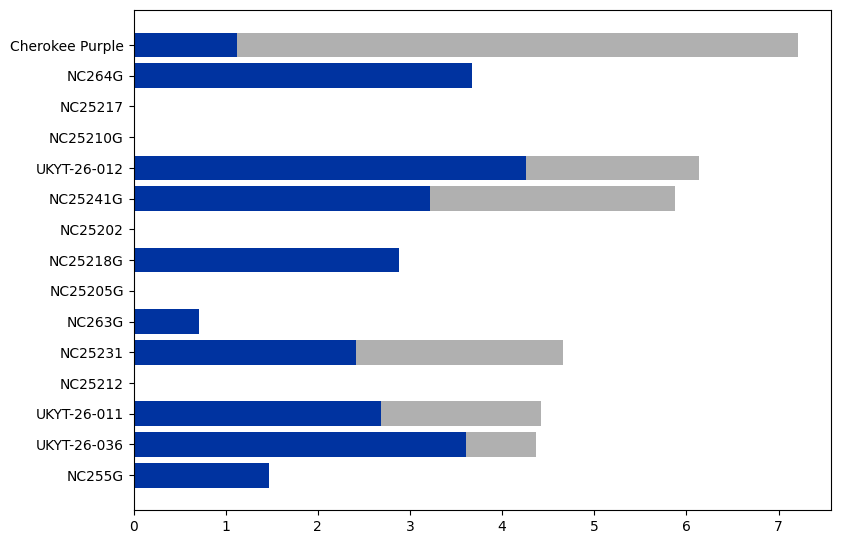

In [10]:
def plot_top15_bars(df, value_col, path, title, xlabel, divide_by_1000=True):
    plot_df = df.sort_values(value_col, ascending=True)
    fig, ax = plt.subplots(figsize=(8.5, 6.5))
    vals = plot_df[value_col] / 1000 if divide_by_1000 else plot_df[value_col]
    ax.barh(plot_df["Genotypes"], vals, color="#0033A0")
    ax.set_xlabel(xlabel)
    ax.set_title(title)
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    for y, v in enumerate(vals):
        label = f"{v:.2f}" if divide_by_1000 else f"{v:.1f}"
        ax.text(
            v + (0.05 if divide_by_1000 else max(vals) * 0.01),
            y,
            label,
            va="center",
            fontsize=8,
            color="#4a4a4a",
        )
    fig.tight_layout()
    fig.savefig(path, dpi=150)
    plt.close(fig)

plot_top15_bars(
    top15_total,
    "total_weight",
    figures / "fig_rc1_top15_total_weight.png",
    "Top 15 by total weight — Robinson (first harvest)",
    "Total weight (kg)",
)

plot_top15_bars(
    top15_mkt,
    "marketable_percentage",
    figures / "fig_rc2_top15_marketable_pct.png",
    "Top 15 by marketable % — Robinson (first harvest)",
    "Marketable percentage",
    divide_by_1000=False,
)

if not top15_count.empty:
    plot_top15_bars(
        top15_count,
        "total_count",
        figures / "fig_rc3_top15_total_count.png",
        "Top 15 by total count — Robinson (first harvest)",
        "Total count",
        divide_by_1000=False,
    )

grade_top = top15_total[
    [
        "Genotypes",
        "total_marketable_weight",
        "total_unmarketable_weight",
        "total_weight",
    ]
].copy()

for col in ["total_marketable_weight", "total_unmarketable_weight"]:
    grade_top[col] = grade_top[col].fillna(0)

grade_top["residual_weight"] = (
    grade_top["total_weight"]
    - grade_top["total_marketable_weight"]
    - grade_top["total_unmarketable_weight"]
).clip(lower=0)

fig, ax = plt.subplots(figsize=(9, 6.5))

plot_df = grade_top.sort_values("total_weight", ascending=True)

y = plot_df["Genotypes"]

mkt = plot_df["total_marketable_weight"] / 1000

umn = plot_df["total_unmarketable_weight"] / 1000

res = plot_df["residual_weight"] / 1000

ax.barh(y, mkt, color="#0033A0", label="Marketable (Grade 1)")

ax.barh(y, umn, left=mkt, color="#B0B0B0", label="Unmarketable")

In [11]:
ax.barh(
    y,
    res,
    left=mkt + umn,
    color="#D8C48A",
    label="Unpartitioned (total only)",
)

ax.set_xlabel("Weight (kg)")

ax.set_title("Composition — top 15 by total weight (Robinson)")

ax.legend(frameon=False, fontsize=9)

ax.spines["top"].set_visible(False)

ax.spines["right"].set_visible(False)

fig.tight_layout()

fig.savefig(figures / "fig_rc4_composition_top15.png", dpi=150)

plt.close(fig)

## Yield and Brix

In [12]:
if join_brix["mean_brix_robinson"].notna().any():
    fig, ax = plt.subplots(figsize=(7.5, 5.5))
    ax.scatter(
        join_brix["mean_brix_robinson"],
        join_brix["total_weight"] / 1000,
        c="#0033A0",
        alpha=0.75,
        edgecolors="white",
        linewidths=0.4,
    )
    for _, row in join_brix.nlargest(5, "total_weight").iterrows():
        ax.annotate(
            row["Genotypes"],
            (row["mean_brix_robinson"], row["total_weight"] / 1000),
            textcoords="offset points",
            xytext=(4, 4),
            fontsize=7,
            color="#4a4a4a",
        )
    ax.set_xlabel("Mean °Brix (Robinson)")
    ax.set_ylabel("Total harvest weight (kg)")
    ax.set_title("Robinson yield vs °Brix (first harvest)")
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    fig.tight_layout()
    fig.savefig(figures / "fig_rc5_yield_vs_brix.png", dpi=150)
    plt.close(fig)

if "Fruit type" in genotype_summary.columns:
    ft = genotype_summary.dropna(subset=["total_weight", "Fruit type"]).copy()
    if not ft.empty:
        ft["Fruit type plot"] = ft["Fruit type"].astype(str).str.strip()
        order = (
            ft.groupby("Fruit type plot")["total_weight"]
            .median()
            .sort_values(ascending=False)
            .index.tolist()
        )
        fig, ax = plt.subplots(figsize=(8, 5))
        data = [ft.loc[ft["Fruit type plot"] == lab, "total_weight"] / 1000 for lab in order]
        ax.boxplot(data, tick_labels=order, vert=True)
        ax.set_ylabel("Total harvest weight (kg)")
        ax.set_title("Robinson total weight by fruit type")
        ax.tick_params(axis="x", labelrotation=20)
        ax.spines["top"].set_visible(False)
        ax.spines["right"].set_visible(False)
        fig.tight_layout()
        fig.savefig(figures / "fig_rc6_weight_by_fruit_type.png", dpi=150)
        plt.close(fig)

## Summary table

In [13]:
review = pd.read_csv("robinson_genotype_summary.csv")
display(review[['Genotypes', 'n_rows', 'total_weight', 'marketable_percentage', 'mean_brix_robinson']].head(10))
print("Exported rows:", len(review))

,Genotypes,n_rows,total_weight,marketable_percentage,mean_brix_robinson
0,Cherokee Purple,1,7210.0,15.617198,5.327555
1,NC264G,1,7153.0,51.418985,5.576568
2,NC25217,1,6632.0,NaN,NaN
3,NC25210G,1,6186.0,NaN,NaN
4,UKYT-26-012,1,6134.0,69.481578,4.828270
5,NC25241G,2,5875.0,54.774468,NaN
6,NC25202,1,5595.0,NaN,NaN
7,NC25218G,1,5542.0,51.894623,5.327555
8,NC25205G,1,4891.0,NaN,4.828270
9,NC263G,1,4825.0,14.694301,NaN


Exported rows: 81


## Figures

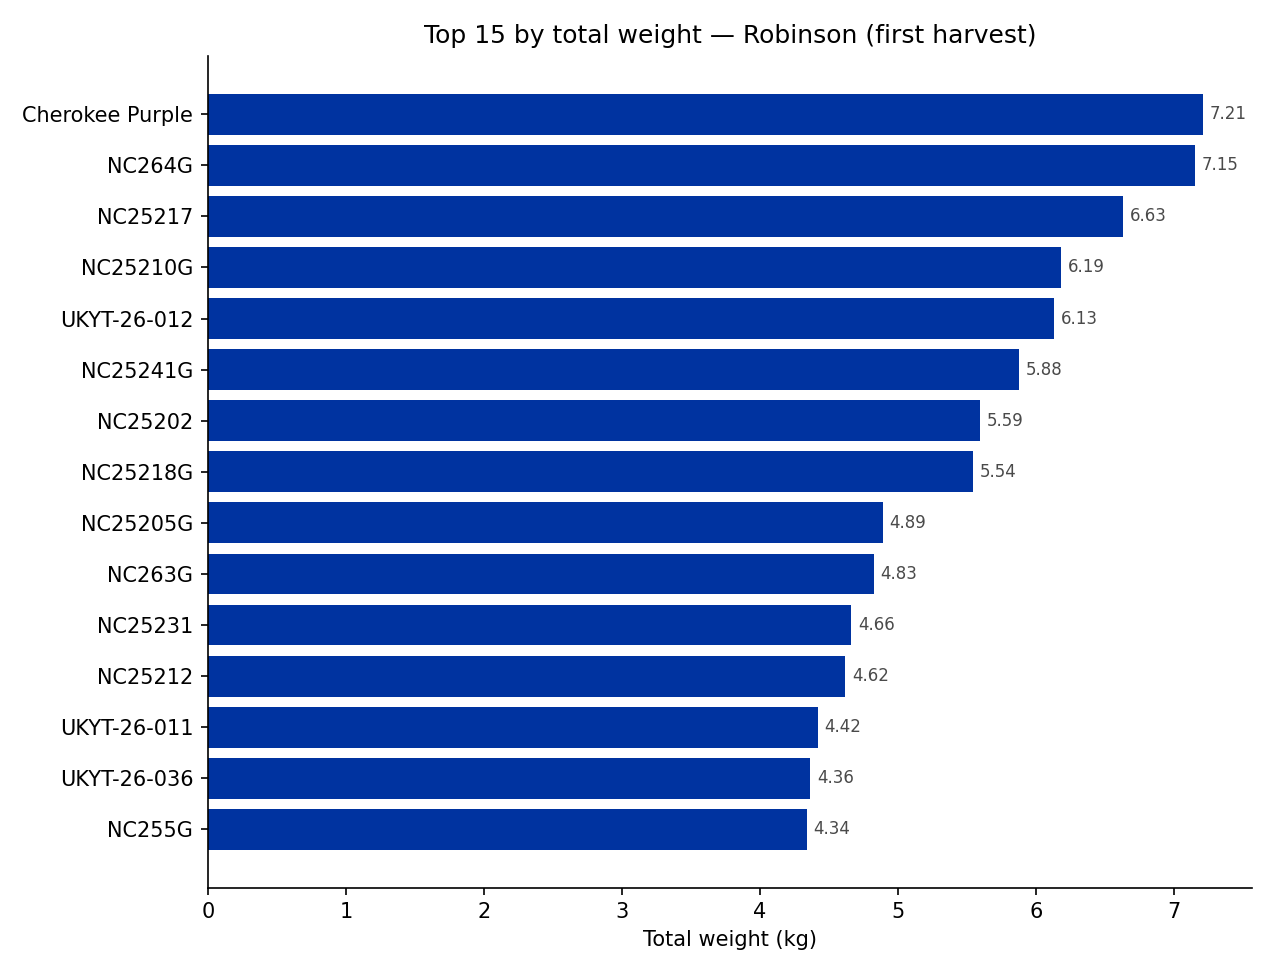

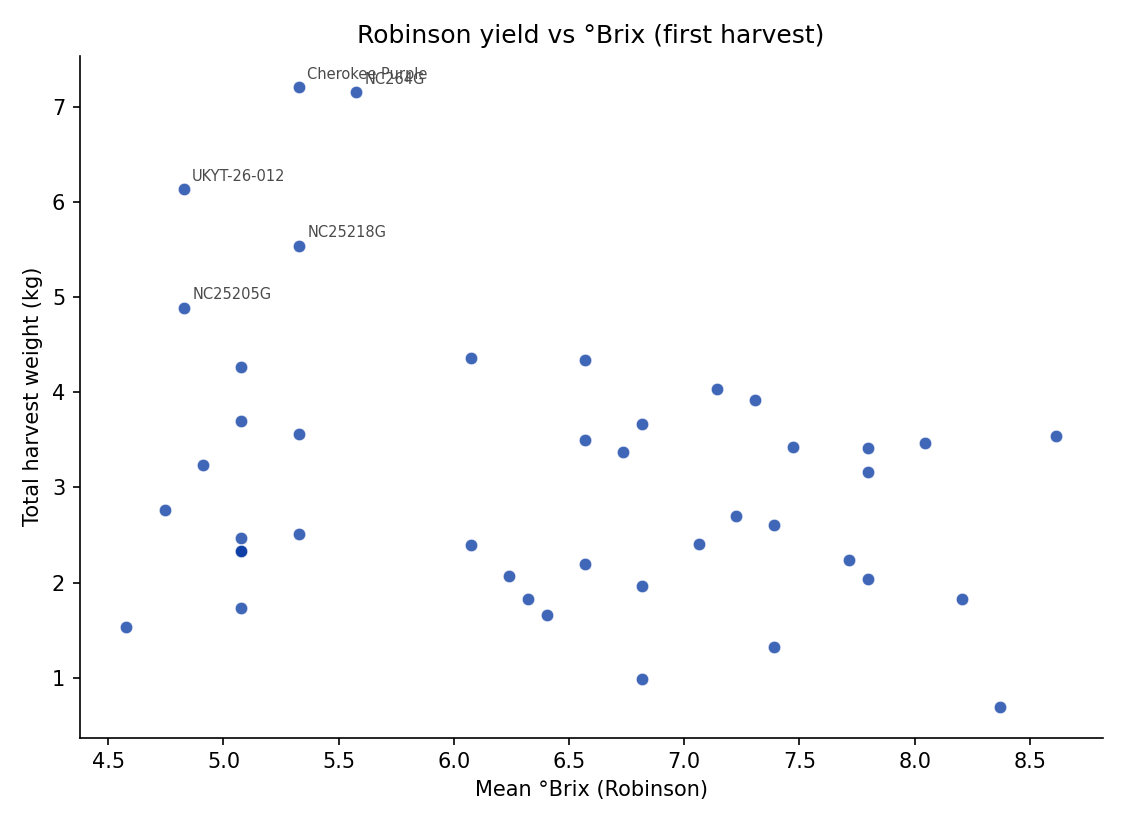

In [14]:
display(Image(filename="figures/fig_rc1_top15_total_weight.png"))
display(Image(filename="figures/fig_rc5_yield_vs_brix.png"))